# 实验报告02：NumPy、SciPy、Matplotlib 与 pandas 数据处理

学号：20244080115　姓名：胡勇彦

In [1]:
import os
import uuid
import hashlib
import platform
import numpy as np
import scipy
import matplotlib
import pandas as pd

STUDENT_ID = 20244080115

CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV", "base")
print(f"[Conda 环境] {CONDA_ENV}")

MACHINE_FP = hashlib.sha256(
    f"{platform.node()} | {platform.machine()} | {platform.system()} | {uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID} - {MACHINE_FP}"
print(f"[学号] {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID] {RUN_ID}")
print("NumPy:", np.__version__, "| SciPy:", scipy.__version__,
      "| pandas:", pd.__version__, "| Matplotlib:", matplotlib.__version__)

[Conda 环境] base
[学号] 20244080115
[机器指纹] aca91e3578be51ad
[RUN_ID] 20244080115 - aca91e3578be51ad
NumPy: 2.5.4 | SciPy: 1.18.1 | pandas: 3.0.6 | Matplotlib: 3.11.2


## 实验1：NumPy 数组、数据类型与索引

### 1. 整数、浮点数、布尔数组及其 dtype/shape/ndim

In [2]:
rng = np.random.default_rng(42)

a_int = np.array([1, 2, 3, 4], dtype=np.int64)
a_float = np.array([1.0, 2.5, 3.7], dtype=np.float64)
a_bool = np.array([True, False, True, False], dtype=bool)

for name, a in [("int", a_int), ("float", a_float), ("bool", a_bool)]:
    print(name, a, "| dtype:", a.dtype, "| shape:", a.shape, "| ndim:", a.ndim)

int [1 2 3 4] | dtype: int64 | shape: (4,) | ndim: 1
float [1.  2.5 3.7] | dtype: float64 | shape: (3,) | ndim: 1
bool [ True False  True False] | dtype: bool | shape: (4,) | ndim: 1


**解释：** NumPy 数组是同质数组，所有元素必须是同一 dtype（如 int64、float64），因此可以向量化高速运算、占用连续内存；Python 列表是异质的，元素可任意类型，每个元素是独立对象，无统一 dtype，数值计算效率低。

### 2. `arange(12)` 变形为 (3,4) 与 (2,3,2)

In [3]:
x = np.arange(12)
x_34 = x.reshape(3, 4)
x_232 = x.reshape(2, 3, 2)
print(x_34)
print(x_34.shape)
print(x_232)
print(x_232.shape)

[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
(3, 4)
[[[ 0  1]
  [ 2  3]
  [ 4  5]]

 [[ 6  7]
  [ 8  9]
  [10 11]]]
(2, 3, 2)


**说明：** 改变形状时各维度长度的乘积必须等于原数组元素总数（12 = 3×4 = 2×3×2），否则报错。

### 3. 对 (3,4) 数组索引：第 2 行、第 1-3 列、大于 6 的元素

In [4]:
row2 = x_34[1]
cols13 = x_34[:, 1:3]
gt6 = x_34[x_34 > 6]
print("第2行:", row2, row2.shape)
print("第1-3列:\n", cols13, cols13.shape)
print("大于6:", gt6, gt6.shape)

第2行: [4 5 6 7] (4,)
第1-3列:
 [[ 1  2]
 [ 5  6]
 [ 9 10]] (3, 2)
大于6: [ 7  8  9 10 11] (5,)


### 4. 逻辑条件选择（括号配合 |、&）

In [5]:
y = np.arange(10)
sel_or = y[(y < 2) | (y > 7)]
sel_and = y[(y > 3) & (y < 7)]
print("小于2或大于7:", sel_or)
print("大于3且小于7:", sel_and)
print("logical_or:", y[np.logical_or(y < 2, y > 7)])
print("logical_and:", y[np.logical_and(y > 3, y < 7)])

小于2或大于7: [0 1 8 9]
大于3且小于7: [4 5 6]
logical_or: [0 1 8 9]
logical_and: [4 5 6]


### 5. 逐元素乘法 vs 矩阵乘法

In [6]:
A = np.array([[1, 2], [3, 4]])
B = np.array([[5, 6], [7, 8]])
print("A * B (逐元素):\n", A * B)
print("np.multiply:\n", np.multiply(A, B))
print("A @ B (矩阵乘法):\n", A @ B)
print("np.matmul:\n", np.matmul(A, B))

A * B (逐元素):
 [[ 5 12]
 [21 32]]
np.multiply:
 [[ 5 12]
 [21 32]]
A @ B (矩阵乘法):
 [[19 22]
 [43 50]]
np.matmul:
 [[19 22]
 [43 50]]


**区别：** `*`/`np.multiply` 是对应位置元素逐一相乘，形状相同即可；`@`/`np.matmul` 是线性代数矩阵乘法，按行乘列求和，要求前一个矩阵的列数等于后一个矩阵的行数。

## 实验2：随机抽样、统计与缺失值

### 1. 1000 个模拟成绩，clip 到 0-100 并统计

In [7]:
np.random.seed(42)
scores = np.random.normal(loc=70, scale=10, size=1000)
scores = np.clip(scores, 0, 100)
print("样本数:", scores.size)
print("最小值:", scores.min())
print("最大值:", scores.max())
print("均值:", scores.mean())
print("标准差:", scores.std())
print("极差:", np.ptp(scores))

样本数: 1000
最小值: 37.58732659930927
最大值: 100.0
均值: 70.18400443523215
标准差: 9.755086339034765
极差: 62.41267340069073


### 2. 不放回抽样：均匀 vs 按大小加权

In [8]:
pool = np.arange(1, 11)
uniform = rng.choice(pool, size=5, replace=False)
weights = pool / pool.sum()
weighted = rng.choice(pool, size=5, replace=False, p=weights)
print("均匀抽样:", uniform)
print("加权抽样:", weighted, "(权重:", np.round(weights, 3), ")")

均匀抽样: [6 4 8 1 5]
加权抽样: [10  9  4  7  5] (权重: [0.018 0.036 0.055 0.073 0.091 0.109 0.127 0.145 0.164 0.182] )


### 3. 随机排列（保留原数组）vs 原地打乱

In [9]:
orig = np.arange(10)
perm = np.random.permutation(orig)
print("permutation 后原数组:", orig)
print("返回的新排列:", perm)
shuf = orig.copy()
np.random.shuffle(shuf)
print("shuffle 后数组:", shuf)

permutation 后原数组: [0 1 2 3 4 5 6 7 8 9]
返回的新排列: [3 8 1 5 9 4 2 7 0 6]
shuffle 后数组: [9 2 4 3 1 0 7 6 8 5]


### 4. 缺失值 nan 的影响

In [10]:
scores_nan = scores.copy()
scores_nan[[9, 19, 29]] = np.nan
print("缺失值个数:", np.isnan(scores_nan).sum())
print("普通均值(np.nan传播):", np.mean(scores_nan))
print("忽略缺失值均值:", np.nanmean(scores_nan))

缺失值个数: 3
普通均值(np.nan传播): nan
忽略缺失值均值: 70.19620743160239


**说明：** 普通统计函数（如 `np.mean`）遇到 nan 会返回 nan，因为 nan 会在运算中传播；必须使用 `np.nanmean`、`np.nanstd` 等 nan 版本函数才能忽略缺失值。

### 5. 含缺失值成绩及序号整理为内存表格（不写磁盘），供实验4使用

In [11]:
mask = np.isnan(scores_nan)
missing_table = pd.DataFrame({
    "index": np.where(mask)[0],
    "score": scores_nan[mask],
})
print(missing_table)

   index  score
0      9    NaN
1     19    NaN
2     29    NaN


## 实验3：SciPy 数值计算与 Matplotlib 可视化

### 1. `scipy.linalg.solve` 解线性方程组

In [12]:
import scipy.linalg as sla

coef = np.array([[3, 1], [1, 2]], dtype=float)
rhs = np.array([9, 8], dtype=float)
sol = sla.solve(coef, rhs)
print("解 x, y =", sol)
print("验证 coef @ sol =", coef @ sol, "应等于", rhs)

解 x, y = [2. 3.]
验证 coef @ sol = [9. 8.] 应等于 [9. 8.]


### 2. `scipy.optimize.root` 求 x²-2 的正负根

In [13]:
import scipy.optimize as sopt

f = lambda x: x ** 2 - 2
for guess in (1.0, -1.0):
    res = sopt.root(f, guess)
    print(f"初始猜测 {guess}: 成功={res.success}, 根={res.x[0]:.10f}, 函数值={res.fun[0]:.2e}")

初始猜测 1.0: 成功=True, 根=1.4142135624, 函数值=-8.88e-16
初始猜测 -1.0: 成功=True, 根=-1.4142135624, 函数值=-8.88e-16


### 3. `minimize` 求 f(x)=x²+x+2 的最小值

In [14]:
g = lambda x: x ** 2 + x + 2
res_min = sopt.minimize(g, x0=3)
print("成功:", res_min.success)
print("极小点 x*:", res_min.x[0])
print("极小值 f(x*):", res_min.fun)
print("解析结果: x*=-0.5, f(-0.5)=1.75")

成功: True
极小点 x*: -0.5000000033806425
极小值 f(x*): 1.75
解析结果: x*=-0.5, f(-0.5)=1.75


### 4. 独立样本 t 检验（固定种子）

In [15]:
import scipy.stats as sst

np.random.seed(42)
sample1 = np.random.normal(0, 1, 100)
sample2 = np.random.normal(1, 1, 100)
tres = sst.ttest_ind(sample1, sample2)
print("t 统计量:", tres.statistic)
print("p 值:", tres.pvalue)
print("0.05 水平结论:", "拒绝原假设，两组均值存在显著差异"
      if tres.pvalue < 0.05 else "不能拒绝原假设")

t 统计量: -8.55145994324873
p 值: 3.292961428703696e-15
0.05 水平结论: 拒绝原假设，两组均值存在显著差异


### 5. 可视化：有效成绩直方图、箱线图、幂函数折线图

C:\Users\胡勇彦\AppData\Local\Temp\ipykernel_23212\1209246597.py:10: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1].boxplot(valid_scores, vert=True)


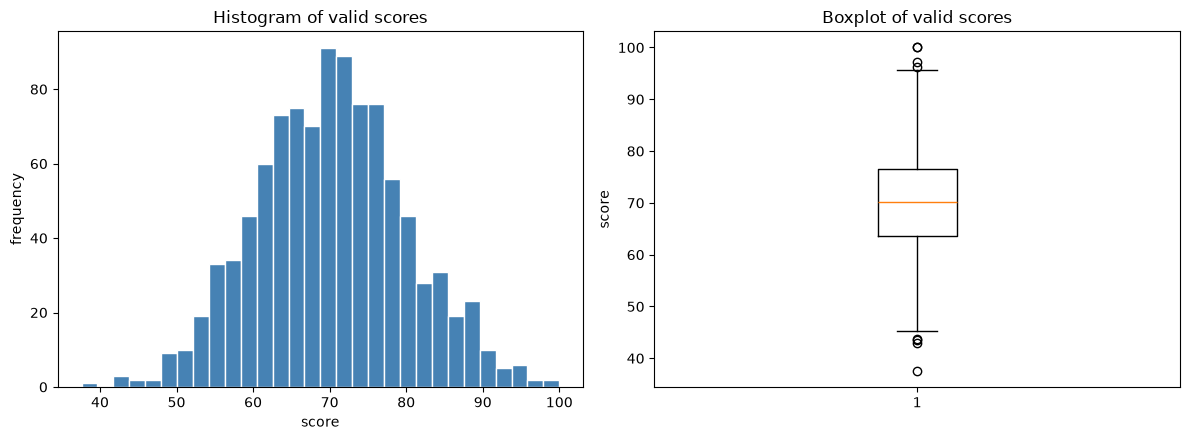

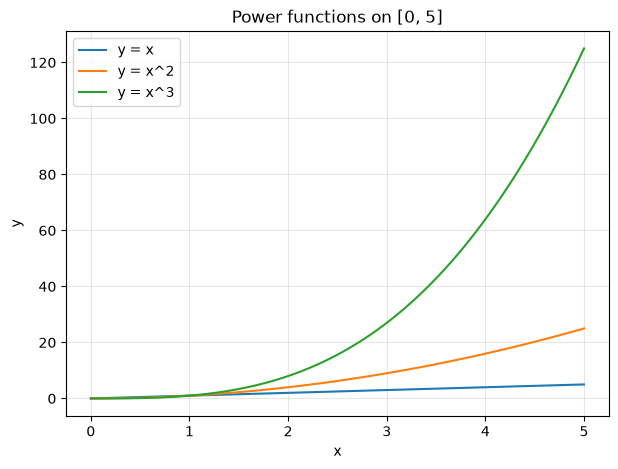

In [16]:
import matplotlib.pyplot as plt

valid_scores = scores_nan[~np.isnan(scores_nan)]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].hist(valid_scores, bins=30, color="steelblue", edgecolor="white")
axes[0].set_title("Histogram of valid scores")
axes[0].set_xlabel("score")
axes[0].set_ylabel("frequency")
axes[1].boxplot(valid_scores, vert=True)
axes[1].set_title("Boxplot of valid scores")
axes[1].set_ylabel("score")
plt.tight_layout()
plt.show()

xs = np.linspace(0, 5, 100)
plt.figure(figsize=(7, 5))
plt.plot(xs, xs, label="y = x")
plt.plot(xs, xs ** 2, label="y = x^2")
plt.plot(xs, xs ** 3, label="y = x^3")
plt.title("Power functions on [0, 5]")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 实验4：pandas Series、DataFrame 与内存中的 CSV 读写

### 1. 创建 DataFrame（行索引为姓名），计算 Total 与 Average

In [17]:
records = {
    "Name": ["Alice", "Bob", "Carol", "David", "Eva", "Frank"],
    "Group": ["A", "A", "B", "B", "A", "B"],
    "Math": [88, 72, 91, 65, 79, 84],
    "English": [90, 68, 85, 73, 92, 77],
    "Python": [95, 80, 89, 70, 86, 82],
}
students = pd.DataFrame(records).set_index("Name")
students["Total"] = students[["Math", "English", "Python"]].sum(axis=1)
students["Average"] = students[["Math", "English", "Python"]].mean(axis=1)
print("行索引:", list(students.index))
print("列名:", list(students.columns))
print(students.head(3))
print(students.describe())

行索引: ['Alice', 'Bob', 'Carol', 'David', 'Eva', 'Frank']
列名: ['Group', 'Math', 'English', 'Python', 'Total', 'Average']
      Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Bob       A    72       68      80    220  73.333333
Carol     B    91       85      89    265  88.333333
            Math    English     Python       Total    Average
count   6.000000   6.000000   6.000000    6.000000   6.000000
mean   79.833333  80.833333  83.666667  244.333333  81.444444
std     9.907909   9.662643   8.547904   25.781130   8.593710
min    65.000000  68.000000  70.000000  208.000000  69.333333
25%    73.750000  74.000000  80.500000  225.750000  75.250000
50%    81.500000  81.000000  84.000000  250.000000  83.333333
75%    87.000000  88.750000  88.250000  263.000000  87.666667
max    91.000000  92.000000  95.000000  273.000000  91.000000


### 2. loc / iloc 读取 Carol，筛选平均分不低于 80

In [18]:
print(students.loc["Carol"])
print(students.iloc[2])
print(students[students["Average"] >= 80])

Group              B
Math              91
English           85
Python            89
Total            265
Average    88.333333
Name: Carol, dtype: object
Group              B
Math              91
English           85
Python            89
Total            265
Average    88.333333
Name: Carol, dtype: object
      Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Carol     B    91       85      89    265  88.333333
Eva       A    79       92      86    257  85.666667
Frank     B    84       77      82    243  81.000000


### 3. 列均值 axis=0 与行均值 axis=1

In [19]:
subjects = ["Math", "English", "Python"]
print("列均值:\n", students[subjects].mean(axis=0))
print("行均值:\n", students[subjects].mean(axis=1))

列均值:
 Math       79.833333
English    80.833333
Python     83.666667
dtype: float64
行均值:
 Name
Alice    91.000000
Bob      73.333333
Carol    88.333333
David    69.333333
Eva      85.666667
Frank    81.000000
dtype: float64


### 4. apply 最高分、agg 汇总、rank 排名

In [20]:
students["Max"] = students[subjects].apply(lambda r: r.max(), axis=1)
print(students[subjects].agg(["min", "mean", "max"]))
students["Python_rank"] = students["Python"].rank(ascending=False, method="min")
print(students[["Python", "Python_rank"]])

           Math    English     Python
min   65.000000  68.000000  70.000000
mean  79.833333  80.833333  83.666667
max   91.000000  92.000000  95.000000
       Python  Python_rank
Name                      
Alice      95          1.0
Bob        80          5.0
Carol      89          2.0
David      70          6.0
Eva        86          3.0
Frank      82          4.0


### 5. 按 Group 分组统计，transform 增加组内 Python 均值

In [21]:
print(students.groupby("Group").agg(size=("Group", "size"),
      Math_mean=("Math", "mean"), English_mean=("English", "mean"),
      Python_mean=("Python", "mean")))
students["Group_Python_mean"] = students.groupby("Group")["Python"].transform("mean")
print(students[["Group", "Python", "Group_Python_mean"]])

       size  Math_mean  English_mean  Python_mean
Group                                            
A         3  79.666667     83.333333    87.000000
B         3  80.000000     78.333333    80.333333
      Group  Python  Group_Python_mean
Name                                  
Alice     A      95          87.000000
Bob       A      80          87.000000
Carol     B      89          80.333333
David     B      70          80.333333
Eva       A      86          87.000000
Frank     B      82          80.333333


### 6. filter 保留 Python 平均分不低于 80 的组

In [22]:
kept = students.groupby("Group").filter(lambda g: g["Python"].mean() >= 80)
print(kept)

      Group  Math  English  Python  Total    Average  Max  Python_rank  \
Name                                                                     
Alice     A    88       90      95    273  91.000000   95          1.0   
Bob       A    72       68      80    220  73.333333   80          5.0   
Carol     B    91       85      89    265  88.333333   91          2.0   
David     B    65       73      70    208  69.333333   73          6.0   
Eva       A    79       92      86    257  85.666667   92          3.0   
Frank     B    84       77      82    243  81.000000   84          4.0   

       Group_Python_mean  
Name                      
Alice          87.000000  
Bob            87.000000  
Carol          80.333333  
David          80.333333  
Eva            87.000000  
Frank          80.333333  


### 7. 协方差矩阵与皮尔森相关系数矩阵

In [23]:
cov_mx = students[subjects].cov()
corr_mx = students[subjects].corr(method="pearson")
print("协方差矩阵:\n", cov_mx)
print("相关系数矩阵:\n", corr_mx)

协方差矩阵:
               Math    English     Python
Math     98.166667  62.566667  74.933333
English  62.566667  93.366667  62.533333
Python   74.933333  62.533333  73.066667
相关系数矩阵:
              Math   English    Python
Math     1.000000  0.653529  0.884776
English  0.653529  1.000000  0.757105
Python   0.884776  0.757105  1.000000


**解释（以 Math-English 为例）：** 协方差为正表示两科成绩倾向于同向变化（一科高另一科也高）；皮尔森相关系数介于 -1 到 1，绝对值越接近 1 线性关系越强。这里相关系数接近 1，说明两科成绩存在很强的正线性相关。